# Option pricing

## Definitions

**The contract**

- Option: a contract giving the holder the right, not the obligation, to buy (call)
  or sell (put) the underlying at the strike K — at T for a European, at any time
  up to T for an American.
- K: strike price, the agreed transaction price
- T: maturity date
- t: the current time
- $\tau$ = T - t: time to maturity
- c, p: price of a European call, put
- C, P: price of an American call, put

**The market**

- S: price of the underlying at time t. Usually a stock, but equally an index, an
  FX rate or a commodity.
- r: continuous risk-free interest rate; the rate at which cash grows with no
  default risk, compounded continuously. It converts amounts between dates: 1 unit
  at t is worth $exp(r \cdot \tau)$ at T, and an amount at T is worth $exp(-r \cdot \tau)$ today.
  This is the opportunity cost of holding money, and the common scale for
  comparing cash at different times.
- y: continuous dividend yield; the rate at which cash leaves the underlying, as a
  fraction of S per unit time, assumed paid continuously. It lowers the drift of S
  from r to (r - y). The option holder receives no dividends, which is why y
  lowers a call and raises a put.
- sigma: annualized asset volatility; the standard deviation of the asset's
  log-returns, scaled to one year. It sets the width of the distribution of S_T.

**Tools**

- PV: present value at t, an amount at a future date expressed in today's money.
  PV(X) = X*exp(-r*tau), so PV(K) is the strike seen from today.
- D: present value at t of future dividends, as known discrete amounts at known
  dates. Discrete counterpart of y: use (S - D) where the continuous version uses
  S*exp(-y*tau).


## Payoff and profit (`mcpricer.payoffs`)

`mcpricer.payoffs` evaluates the payoff for call and put.

### Payoff
The payoff is what the contract pays at T, as a function of S_T:

      call: max(S_T - K, 0)
      put:  max(K - S_T, 0)

At T there is no uncertainty left: given S_T, the payoff is just a number. All the
randomness sits in S_T, and that separation is what makes Monte Carlo possible.

The payoff is never negative, since the holder is not obliged to exercise.

The payoff is flat on one side and kinked at K, so it is not differentiable there.

The payoff plays the role of a detector response function.

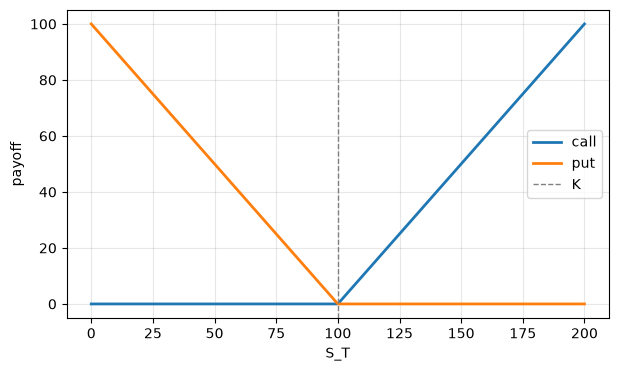

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mcpricer import payoffs

K = 100.0
S_T = np.linspace(0, 200, 400)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(S_T, payoffs.call_payoff(S_T, K=K), lw=2, label="call")
ax.plot(S_T, payoffs.put_payoff(S_T, K=K), lw=2, label="put")
ax.axvline(K, ls="--", color="grey", lw=1, label="K")
ax.set_xlabel("S_T")
ax.set_ylabel("payoff")
ax.legend()
ax.grid(alpha=0.3)

### Profit
The profit can be negative, because the option is paid for at t:

      profit = payoff(S_T) - c*exp(r*tau)

c is addressed later.

## Model for S_T (`mcpricer.models`)

### No-arbitrage
No-arbitrage is the concept that a position which costs nothing, cannot lose, and may
gain does not exist. It is not a claim that markets are fair or efficient, and it is
self-enforcing: taking such a position is what removes it.

An example. A stock trades at 100, r is 5%, there are no dividends, and a one-year
forward on it quotes 110. Selling a forward means committing to deliver the stock at T
for a price agreed today, so: borrow 100, buy the stock, sell the forward. At maturity,
deliver the stock already held, receive 110, repay 100*exp(0.05) = 105.13, and keep
4.87. No capital was committed, and S_T does not appear in the result: whatever the
stock does, the 110 is fixed. That is what makes it an arbitrage rather than a bet that
happened to pay.

It cannot persist, because the trade itself moves the prices it relies on. Buying the
stock is demand on the spot market and pushes S up; selling the forward is supply and
pushes the forward down. The margin, forward - S*exp(r*tau), is eroded from both sides
until

      forward = S*exp((r-y)*tau)

Gaps like this do appear in practice, and are closed in seconds by desks that do only
this. The assumption is not that they never occur, but that they are closed fast enough
to price as if they never do.

Two consequences carry over to everything below.

It replaces forecasting. The drift (r - y) is not a view that the stock will earn r.
Any other drift would hand out free money, so the value is forced rather than chosen.

It constrains prices relative to each other, not in absolute terms. No-arbitrage never
says whether S at 100 is cheap or expensive. It says that once S is 100, the forward
and the option are pinned to it. This is also why no expected return on the stock
appears in any pricing formula: the option is not valued on its own, but against the
stock.

### Building the model
Pricing the option requires knowing S_T, in particular its distribution. While S is
observed today, S_T is not and is uncertain. By no-arbitrage the mean of S_T is fixed,

      E[S_T] = S*exp((r-y)*tau)

because any other value would turn the forward trade above into a riskless profit.
Modelling S_T is therefore assessing its distribution about this mean value.

Two constraints on that distribution.

1. S cannot go negative. A price of zero is default, below zero is meaningless.
   Additive noise of constant size crosses zero sooner or later, so the noise has to
   scale with S, and what gets modelled is the relative move rather than the absolute
   one.

2. Uncertainty is modelled as a Brownian motion. It is the simplest process with the
   properties needed here:

   - no memory: what happened yesterday does not change today's distribution of returns
   - stationary: the distribution of a move depends only on the length of the interval,
     not on when it starts
   - variances add across intervals, so the variance grows with tau and the standard
     deviation grows as sqrt(tau)
   - increments are normal, being sums of many independent smaller moves

   It is the same Wiener process as in diffusion, so sigma*sqrt(tau) plays the role of
   a diffusion length.

### The model

Putting the pieces together: noise proportional to S, driven by a Brownian motion, with
the drift fixed by no-arbitrage. That is geometric Brownian motion,

      dS = (r - y)*S*dt + sigma*S*dW

For a European payoff there is no need to step through time, because the equation has an
exact solution at T:

      S_T = S*exp((r - y - sigma^2/2)*tau + sigma*sqrt(tau)*Z),    Z ~ N(0, 1)

The exponent is normal, so S_T is lognormal, and for a lognormal the mean is not the
exponential of the mean of the exponent — an extra sigma^2*tau/2 appears.

Without the correction the mean would be

      S*exp((r - y)*tau + sigma^2*tau/2)

which sits above the forward, and by the argument above that is an arbitrage.
Subtracting sigma^2/2 from the drift cancels the extra term exactly and leaves

      E[S_T] = S*exp((r - y)*tau)

So the term is forced by the constraint on the mean, not chosen. The same term also
comes out of Ito's lemma when changing variable from S to ln S, which is the usual
route to it; the constraint on the mean is the reason it has to be there at all.

### The price

With a distribution for S_T, the price is the discounted expected payoff:

      price = exp(-r*tau) * E[payoff(S_T)]
            = exp(-r*tau) * integral payoff(S_T) p(S_T) dS_T

This is the same shape as a tally: a distribution folded with a response function. The
payoff is the response function, S_T is the variable being sampled, and the price is the
mean score.

Monte Carlo estimates this integral by sampling S_T. For a vanilla call under this model
it can also be done in closed form, which is the next section.

sampled mean   105.1345   S0*exp((r-y)*tau)            105.1271
sampled median 103.0407   S0*exp((r-y-sigma^2/2)*tau)  103.0455


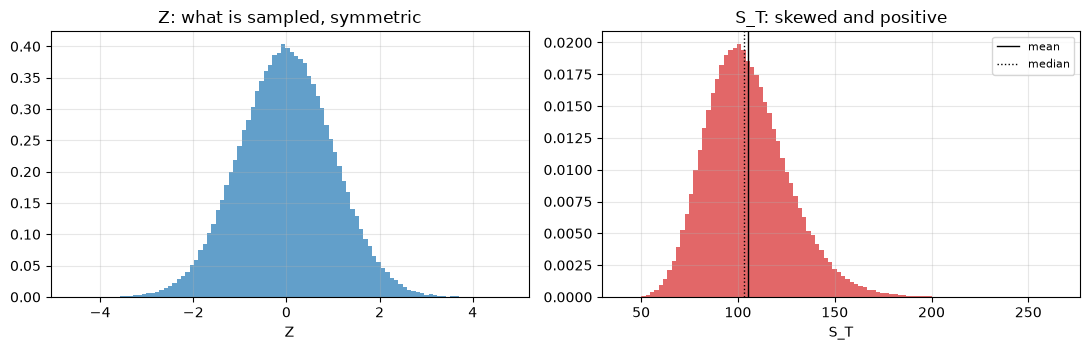

In [2]:
from mcpricer import models

S0, r, y, sigma, tau = 100.0, 0.05, 0.0, 0.20, 1.0
rng = np.random.default_rng(0)

Z = rng.normal(size=200_000)
S_T_samples = models.terminal_price(Z, r=r, T=tau, S0=S0, sigma=sigma, y=y)

print(f"sampled mean   {S_T_samples.mean():8.4f}   S0*exp((r-y)*tau)            {S0 * np.exp((r - y)
* tau):8.4f}")
print(f"sampled median {np.median(S_T_samples):8.4f}   S0*exp((r-y-sigma^2/2)*tau)  {S0 * np.exp((r
- y - 0.5 * sigma**2) * tau):8.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

ax1.hist(Z, bins=100, density=True, color="C0", alpha=0.7)
ax1.set_title("Z: what is sampled, symmetric")
ax1.set_xlabel("Z")

ax2.hist(S_T_samples, bins=100, density=True, color="C3", alpha=0.7)
ax2.axvline(S_T_samples.mean(), color="k", lw=1, label="mean")
ax2.axvline(np.median(S_T_samples), color="k", ls=":", lw=1, label="median")
ax2.set_title("S_T: skewed and positive")
ax2.set_xlabel("S_T")
ax2.legend(fontsize=8)

for ax in (ax1, ax2):
  ax.grid(alpha=0.3)
fig.tight_layout()

## Reference price (`mcpricer.analytical`)

For a European call under this model the integral can be done by hand. The payoff
splits: max(S_T - K, 0) equals (S_T - K) when S_T > K and zero otherwise, so the
integral becomes two integrals over a truncated lognormal, each with a closed form. The
result is Black-Scholes:

      c = S*exp(-y*tau)*Phi(d1) - K*exp(-r*tau)*Phi(d2)

      d1 = (ln(S/K) + (r - y + sigma^2/2)*tau) / (sigma*sqrt(tau))
      d2 = d1 - sigma*sqrt(tau)

where Phi is the standard normal CDF, `norm.cdf` in the code.

The two terms are the two pieces of the payoff. Phi(d2) is the probability of finishing
in the money, under the risk-neutral measure. From the model,

      S_T > K
      Z > (ln(K/S) - (r - y - sigma^2/2)*tau) / (sigma*sqrt(tau)) = -d2

so P(S_T > K) = P(Z > -d2) = Phi(d2) by symmetry. The term K*exp(-r*tau)*Phi(d2) is
then the present value of what is paid, times the probability of paying it.

Phi(d1) is not that same probability. It is the delta of the call, and as a probability
it belongs to a different measure, the one using the stock as numeraire instead of the
cash account.

In this project Black-Scholes is used as a benchmark: it prices a simple case, the
European vanilla option, against which the Monte Carlo estimators are compared.

In [3]:
from scipy.stats import norm

from mcpricer import analytical

c = analytical.black_scholes_call(S0, K, r, sigma, tau, y=y)

d1 = (np.log(S0 / K) + (r - y + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
d2 = d1 - sigma * np.sqrt(tau)

discounted = np.exp(-r * tau) * payoffs.call_payoff(S_T_samples, K=K)
mc = discounted.mean()
se = discounted.std(ddof=1) / np.sqrt(len(discounted))

print(f"Black-Scholes      {c:.6f}")
print(f"Monte Carlo        {mc:.6f} +/- {se:.6f}   ({len(S_T_samples):,} samples)")
print(f"difference         {(mc - c) / se:+.2f} standard errors")
print()
print(f"Phi(d2)            {norm.cdf(d2):.4f}")
print(f"sampled P(S_T>K)   {np.mean(S_T_samples > K):.4f}")

Black-Scholes      10.450584
Monte Carlo        10.464451 +/- 0.032937   (200,000 samples)
difference         +0.42 standard errors

Phi(d2)            0.5596
sampled P(S_T>K)   0.5603
